In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from scipy.stats import chi2_contingency, f_oneway

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import pandas as pd

df = pd.read_csv("/data.csv", sep=";")

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

Dataset loaded successfully!
Shape of dataset: (4424, 37)


In [ ]:
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 4424
Number of columns: 37


In [ ]:
print("Columns in the dataset:\n")

for i, column in enumerate(df.columns, start=1):
    print(i, "-", column)

Columns in the dataset:

1 - Marital status
2 - Application mode
3 - Application order
4 - Course
5 - Daytime/evening attendance	
6 - Previous qualification
7 - Previous qualification (grade)
8 - Nacionality
9 - Mother's qualification
10 - Father's qualification
11 - Mother's occupation
12 - Father's occupation
13 - Admission grade
14 - Displaced
15 - Educational special needs
16 - Debtor
17 - Tuition fees up to date
18 - Gender
19 - Scholarship holder
20 - Age at enrollment
21 - International
22 - Curricular units 1st sem (credited)
23 - Curricular units 1st sem (enrolled)
24 - Curricular units 1st sem (evaluations)
25 - Curricular units 1st sem (approved)
26 - Curricular units 1st sem (grade)
27 - Curricular units 1st sem (without evaluations)
28 - Curricular units 2nd sem (credited)
29 - Curricular units 2nd sem (enrolled)
30 - Curricular units 2nd sem (evaluations)
31 - Curricular units 2nd sem (approved)
32 - Curricular units 2nd sem (grade)
33 - Curricular units 2nd sem (without 

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [ ]:
missing_values = df.isnull().sum()

print("Missing values in each column:\n")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder              

In [ ]:
duplicates = df.duplicated().sum()

print("Number of duplicate records:", duplicates)

Number of duplicate records: 0


In [ ]:
print("Student Outcome Distribution:")
print(df["Target"].value_counts())

Student Outcome Distribution:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [ ]:
print("\nStudent Outcome Percentage:")
print(
    (df["Target"].value_counts(normalize=True) * 100).round(2)
)


Student Outcome Percentage:
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64


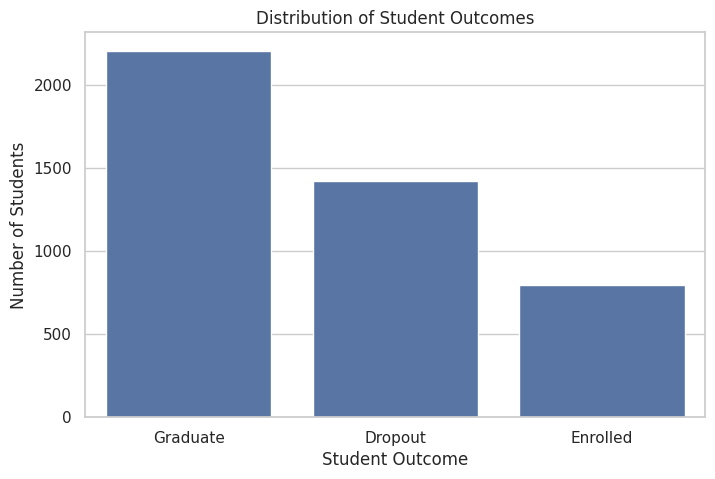

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Target",
    order=df["Target"].value_counts().index
)

plt.title("Distribution of Student Outcomes")
plt.xlabel("Student Outcome")
plt.ylabel("Number of Students")

plt.show()

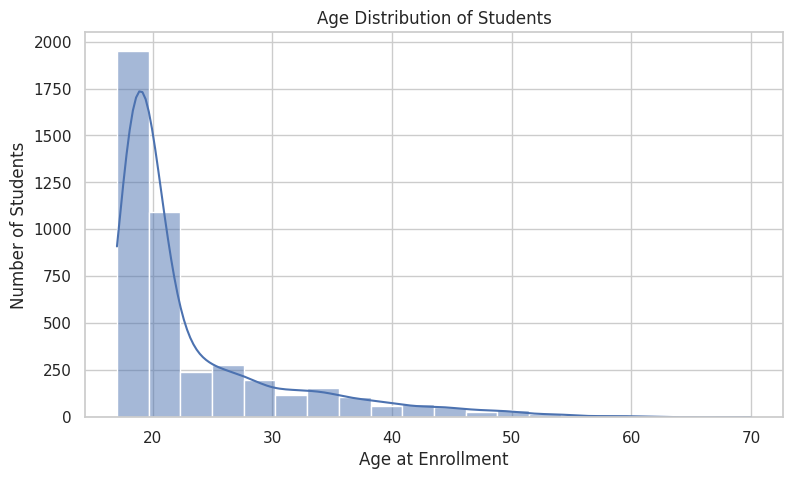

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age at enrollment",
    bins=20,
    kde=True
)

plt.title("Age Distribution of Students")
plt.xlabel("Age at Enrollment")
plt.ylabel("Number of Students")

plt.show()

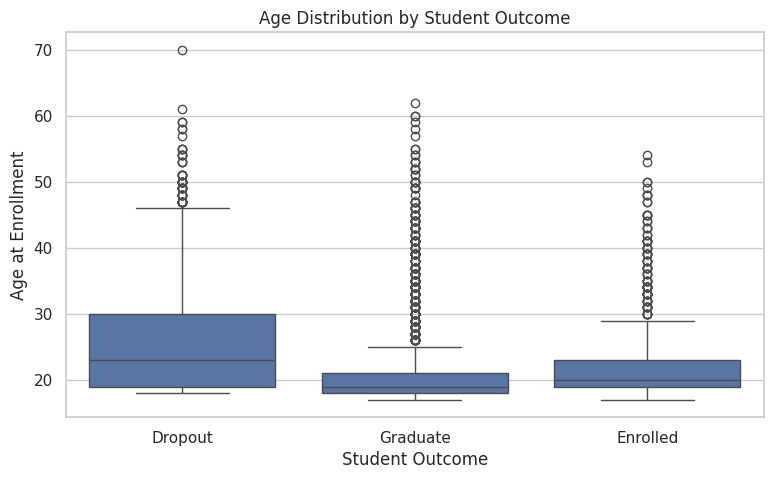

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="Age at enrollment"
)

plt.title("Age Distribution by Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Age at Enrollment")

plt.show()

In [ ]:
#admission grade
print("Admission Grade Statistics:")
print(df["Admission grade"].describe())

Admission Grade Statistics:
count    4424.000000
mean      126.978119
std        14.482001
min        95.000000
25%       117.900000
50%       126.100000
75%       134.800000
max       190.000000
Name: Admission grade, dtype: float64


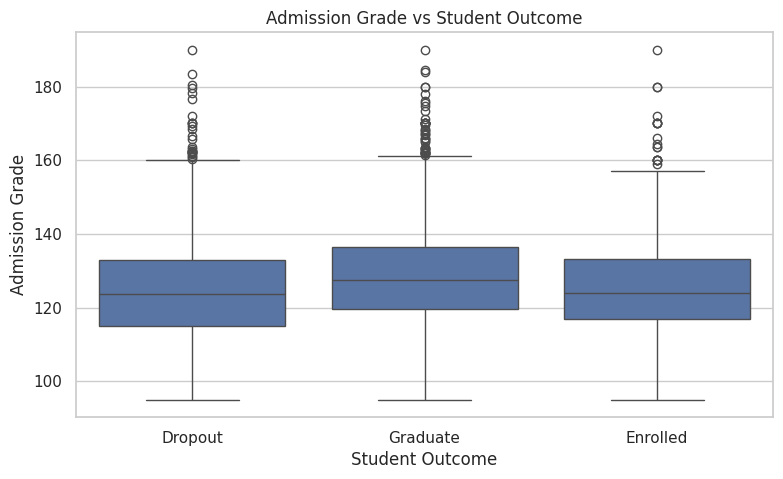

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="Admission grade"
)

plt.title("Admission Grade vs Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Admission Grade")

plt.show()

In [ ]:
#scholarship analysis
scholarship_table = pd.crosstab(
    df["Scholarship holder"],
    df["Target"]
)

print(scholarship_table)

Target              Dropout  Enrolled  Graduate
Scholarship holder                             
0                      1287       664      1374
1                       134       130       835


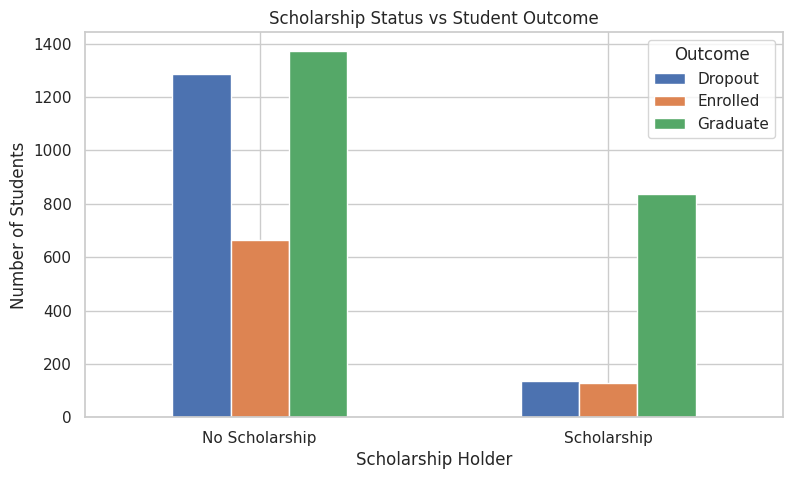

In [ ]:
scholarship_table.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Scholarship Status vs Student Outcome")
plt.xlabel("Scholarship Holder")
plt.ylabel("Number of Students")

plt.xticks(
    ticks=[0, 1],
    labels=["No Scholarship", "Scholarship"],
    rotation=0
)

plt.legend(title="Outcome")

plt.show()

In [ ]:
#tution fees analysis
tuition_table = pd.crosstab(
    df["Tuition fees up to date"],
    df["Target"]
)

print(tuition_table)

Target                   Dropout  Enrolled  Graduate
Tuition fees up to date                             
0                            457        42        29
1                            964       752      2180


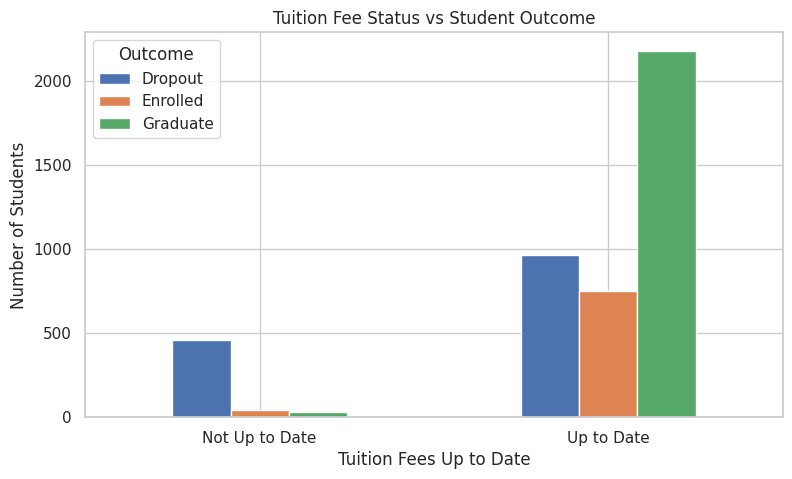

In [ ]:
tuition_table.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Tuition Fee Status vs Student Outcome")
plt.xlabel("Tuition Fees Up to Date")
plt.ylabel("Number of Students")

plt.xticks(
    ticks=[0, 1],
    labels=["Not Up to Date", "Up to Date"],
    rotation=0
)

plt.legend(title="Outcome")

plt.show()

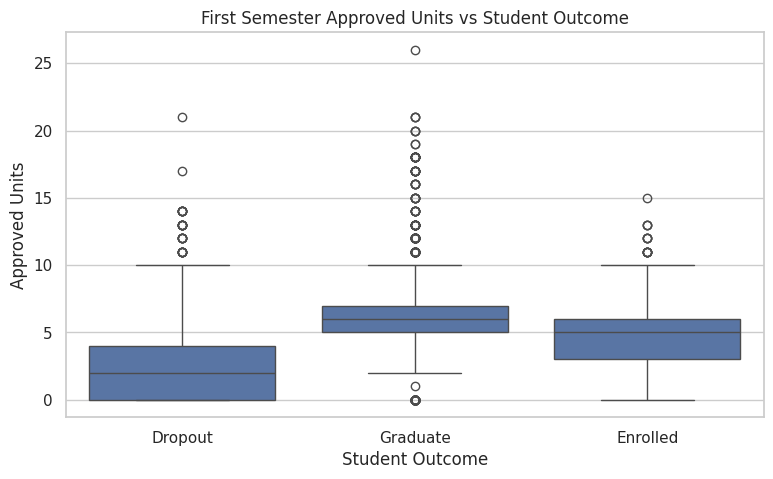

In [ ]:
#First Semester Academic Performance
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 1st sem (approved)"
)

plt.title("First Semester Approved Units vs Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Approved Units")

plt.show()

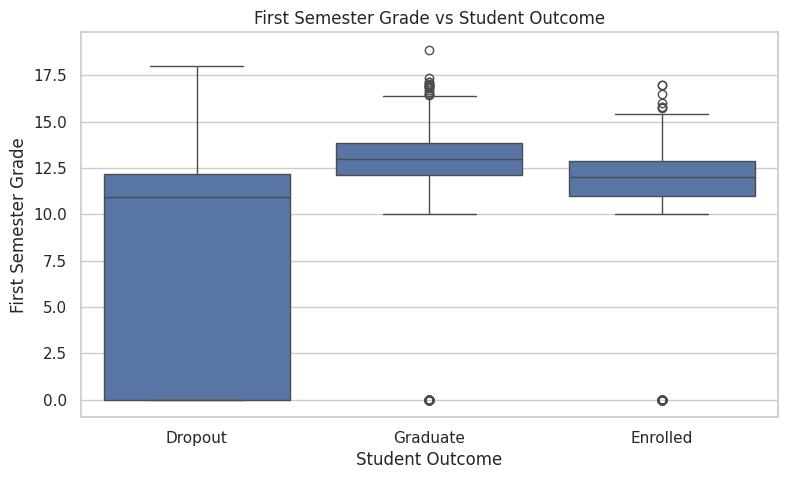

In [ ]:
#first sem arde card
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 1st sem (grade)"
)

plt.title("First Semester Grade vs Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("First Semester Grade")

plt.show()

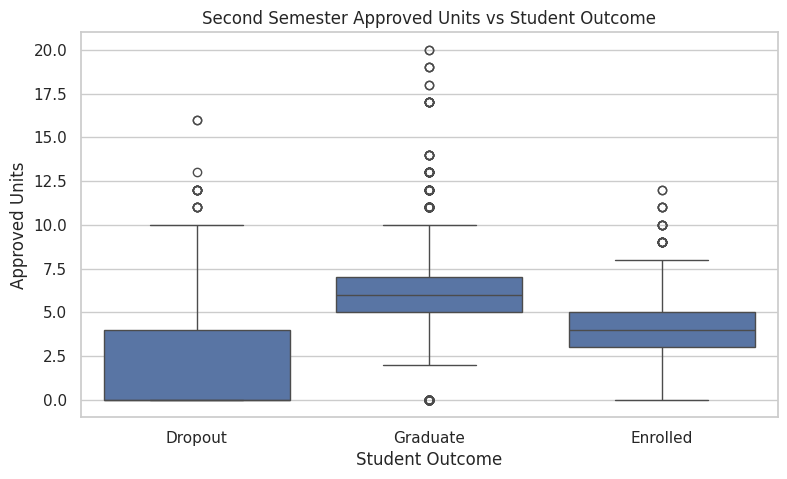

In [ ]:
# second sem performance
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 2nd sem (approved)"
)

plt.title("Second Semester Approved Units vs Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Approved Units")

plt.show()

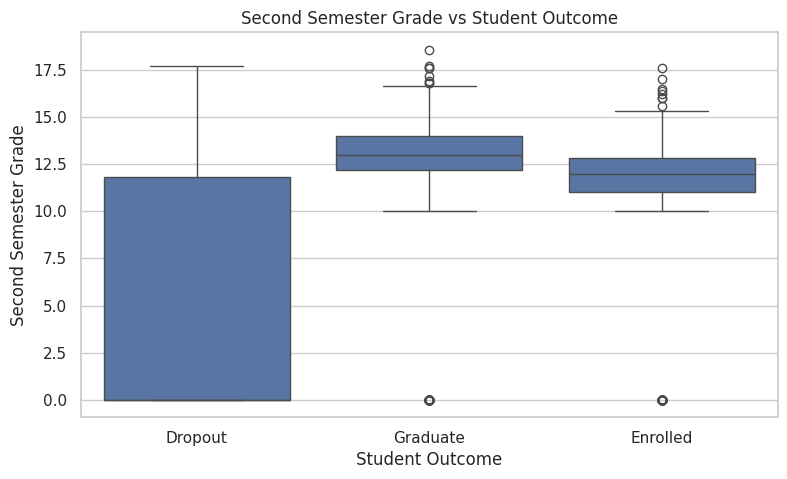

In [ ]:
#second sem rade card
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 2nd sem (grade)"
)

plt.title("Second Semester Grade vs Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Second Semester Grade")

plt.show()

/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


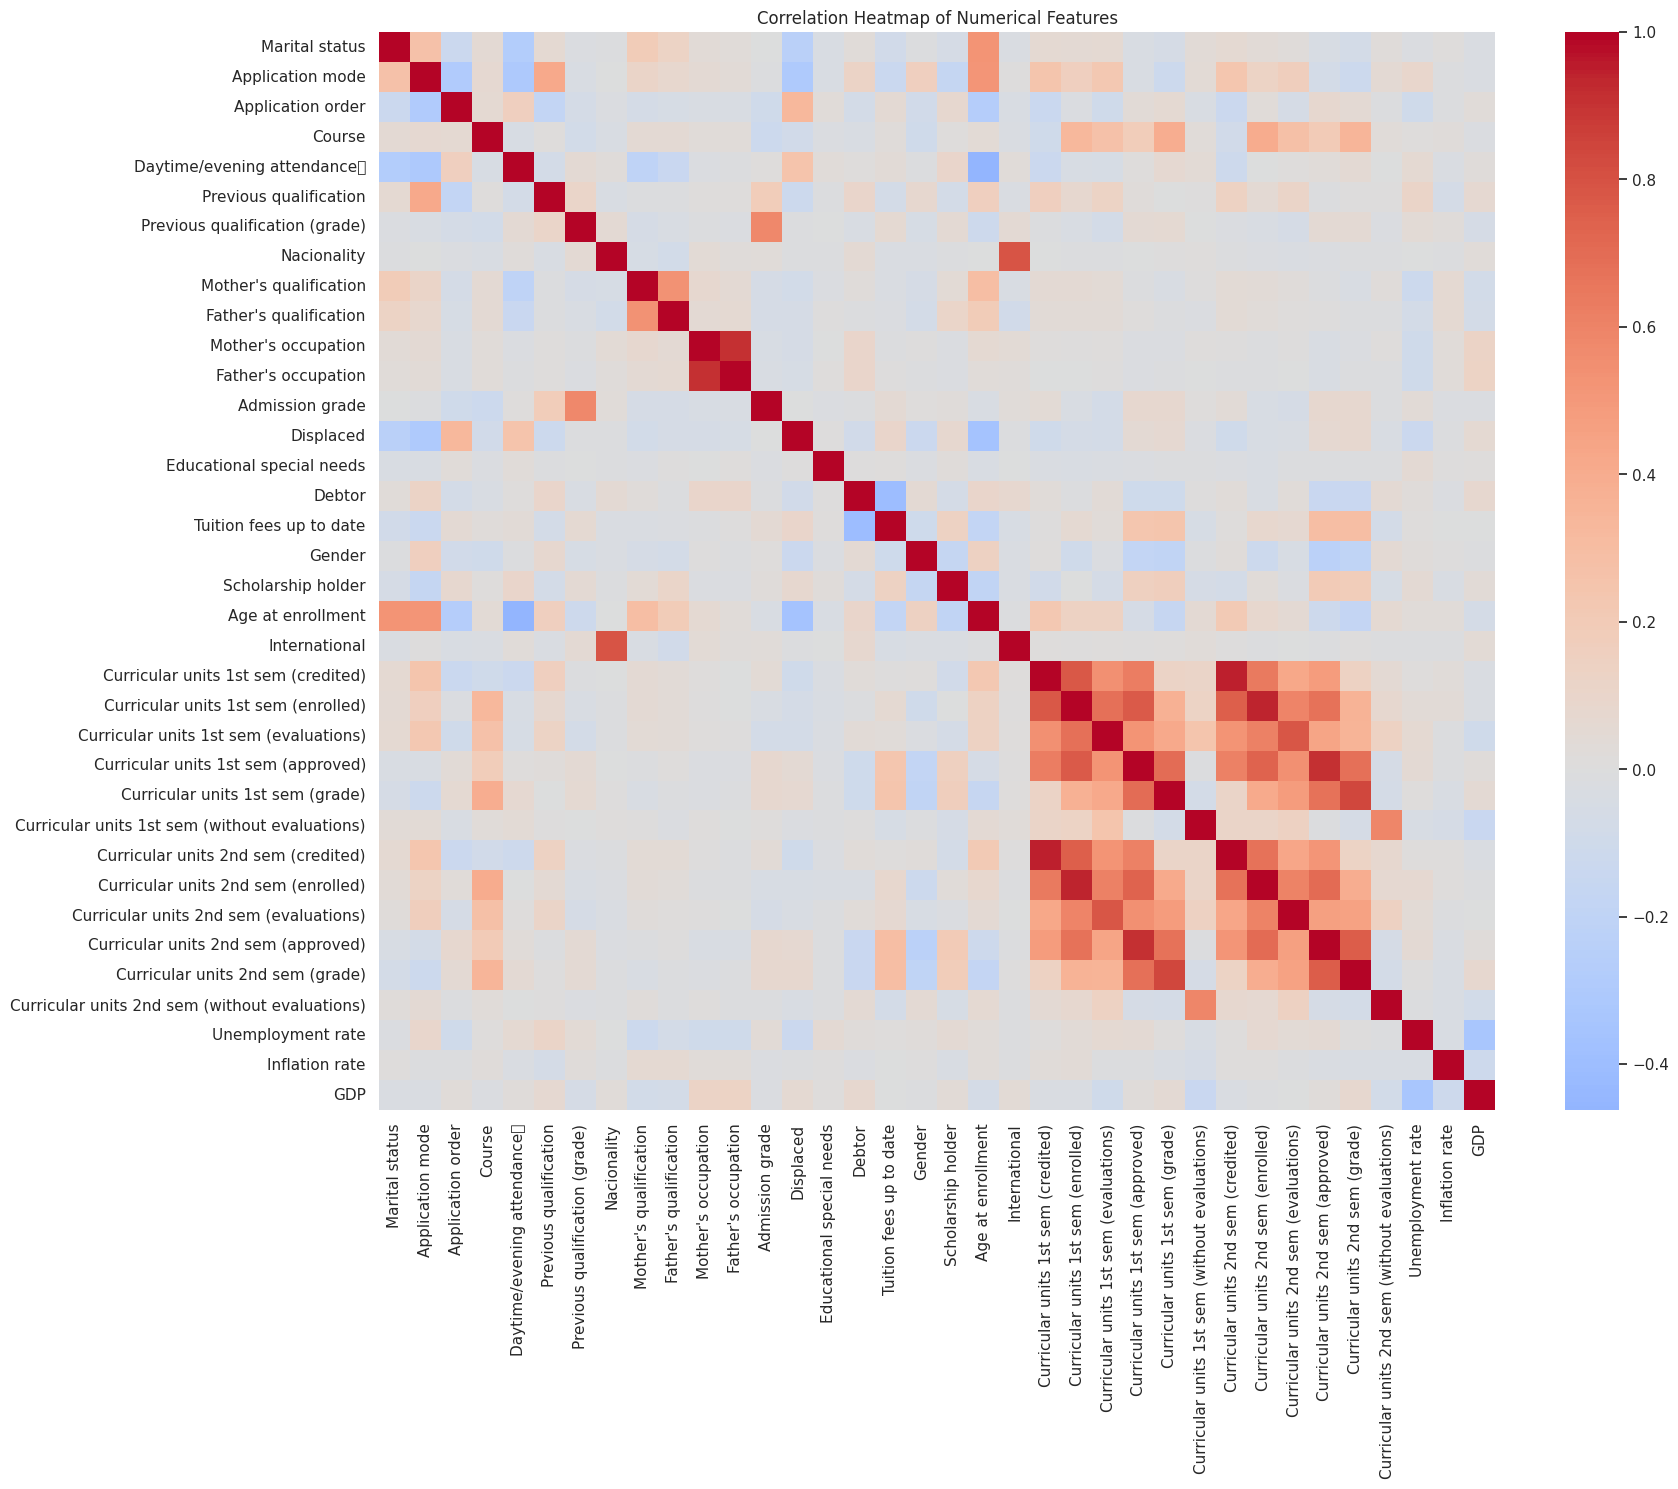

In [ ]:
#correlation heatmap
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")

plt.show()

In [ ]:
#Statistical Analysis
#Chi-Square Test: Scholarship vs Outcome
from scipy.stats import chi2_contingency

# Create contingency table
contingency_table = pd.crosstab(
    df["Scholarship holder"],
    df["Target"]
)

print("Contingency Table:")
print(contingency_table)

# Perform Chi-Square test
chi2, p_value, degrees_of_freedom, expected = chi2_contingency(
    contingency_table
)

print("\nChi-Square Test Results")
print("----------------------")
print("Chi-square value:", round(chi2, 4))
print("p-value:", round(p_value, 4))
print("Degrees of freedom:", degrees_of_freedom)

# Interpretation
if p_value < 0.05:
    print("\nConclusion: There is a statistically significant association")
    print("between scholarship status and student outcome.")
else:
    print("\nConclusion: There is no statistically significant association")
    print("between scholarship status and student outcome.")

Contingency Table:
Target              Dropout  Enrolled  Graduate
Scholarship holder                             
0                      1287       664      1374
1                       134       130       835

Chi-Square Test Results
----------------------
Chi-square value: 409.9431
p-value: 0.0
Degrees of freedom: 2

Conclusion: There is a statistically significant association
between scholarship status and student outcome.


In [ ]:
#One-Way ANOVA: Age vs Outcome
from scipy.stats import f_oneway

# Separate age groups
dropout_age = df[
    df["Target"] == "Dropout"
]["Age at enrollment"]

enrolled_age = df[
    df["Target"] == "Enrolled"
]["Age at enrollment"]

graduate_age = df[
    df["Target"] == "Graduate"
]["Age at enrollment"]

# Perform one-way ANOVA
f_statistic, p_value = f_oneway(
    dropout_age,
    enrolled_age,
    graduate_age
)

print("One-Way ANOVA Results")
print("---------------------")
print("F-statistic:", round(f_statistic, 4))
print("p-value:", round(p_value, 4))

if p_value < 0.05:
    print("\nConclusion: There is a statistically significant difference")
    print("in age among the three student outcome groups.")
else:
    print("\nConclusion: There is no statistically significant difference")
    print("in age among the three student outcome groups.")

One-Way ANOVA Results
---------------------
F-statistic: 154.7121
p-value: 0.0

Conclusion: There is a statistically significant difference
in age among the three student outcome groups.


In [ ]:
#Basic Statistical Summary
statistics = df[
    [
        "Age at enrollment",
        "Admission grade",
        "Curricular units 1st sem (approved)",
        "Curricular units 1st sem (grade)",
        "Curricular units 2nd sem (approved)",
        "Curricular units 2nd sem (grade)"
    ]
].describe().T

statistics

,count,mean,std,min,25%,50%,75%,max
Age at enrollment,4424.0,23.265145,7.587816,17.0,19.00,20.000000,25.000000,70.000000
Admission grade,4424.0,126.978119,14.482001,95.0,117.90,126.100000,134.800000,190.000000
Curricular units 1st sem (approved),4424.0,4.706600,3.094238,0.0,3.00,5.000000,6.000000,26.000000
Curricular units 1st sem (grade),4424.0,10.640822,4.843663,0.0,11.00,12.285714,13.400000,18.875000
Curricular units 2nd sem (approved),4424.0,4.435805,3.014764,0.0,2.00,5.000000,6.000000,20.000000
Curricular units 2nd sem (grade),4424.0,10.230206,5.210808,0.0,10.75,12.200000,13.333333,18.571429


In [ ]:
#Compare Dropout Students
dropout_students = df[
    df["Target"] == "Dropout"
]

print("Total Dropout Students:", len(dropout_students))

print(
    "\nAverage Age:",
    round(dropout_students["Age at enrollment"].mean(), 2)
)

print(
    "Average Admission Grade:",
    round(dropout_students["Admission grade"].mean(), 2)
)

print(
    "Average First Semester Approved Units:",
    round(
        dropout_students[
            "Curricular units 1st sem (approved)"
        ].mean(),
        2
    )
)

print(
    "Average First Semester Grade:",
    round(
        dropout_students[
            "Curricular units 1st sem (grade)"
        ].mean(),
        2
    )
)

print(
    "Average Second Semester Approved Units:",
    round(
        dropout_students[
            "Curricular units 2nd sem (approved)"
        ].mean(),
        2
    )
)

print(
    "Average Second Semester Grade:",
    round(
        dropout_students[
            "Curricular units 2nd sem (grade)"
        ].mean(),
        2
    )
)

Total Dropout Students: 1421

Average Age: 26.07
Average Admission Grade: 124.96
Average First Semester Approved Units: 2.55
Average First Semester Grade: 7.26
Average Second Semester Approved Units: 1.94
Average Second Semester Grade: 5.9


In [ ]:
# Select features available at the early stage

semester_columns = [
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",
    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (without evaluations)"
]

# Create early-prediction feature dataset
X_early = df.drop(columns=["Target"] + semester_columns)
y = df["Target"]

print("Early-prediction dataset created successfully!")
print("Number of features:", X_early.shape[1])
print("Number of students:", X_early.shape[0])

print("\nFeatures used:")
print(X_early.columns.tolist())

Early-prediction dataset created successfully!
Number of features: 24
Number of students: 4424

Features used:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Unemployment rate', 'Inflation rate', 'GDP']


In [ ]:
# Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_early,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data split successfully!")

print("\nTraining data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Data split successfully!

Training data:
X_train: (3539, 24)
y_train: (3539,)

Testing data:
X_test: (885, 24)
y_test: (885,)

Training target distribution:
Target
Graduate    1767
Dropout     1137
Enrolled     635
Name: count, dtype: int64

Testing target distribution:
Target
Graduate    442
Dropout     284
Enrolled    159
Name: count, dtype: int64


In [ ]:
stratify=y

In [ ]:
# Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create Logistic Regression pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Make predictions
y_pred_logistic = logistic_model.predict(X_test)

# Calculate accuracy
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Results")
print("--------------------------------")
print("Accuracy:", round(logistic_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))

Logistic Regression Results
--------------------------------
Accuracy: 62.49 %

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.65      0.59      0.62       284
    Enrolled       0.27      0.04      0.08       159
    Graduate       0.63      0.86      0.72       442

    accuracy                           0.62       885
   macro avg       0.52      0.50      0.47       885
weighted avg       0.57      0.62      0.57       885



In [ ]:
# Step 26: Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create Decision Tree model
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=8
)

# Train the model
decision_tree.fit(X_train, y_train)

# Make predictions
y_pred_tree = decision_tree.predict(X_test)

# Calculate accuracy
tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Results")
print("--------------------------------")
print("Accuracy:", round(tree_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))

Decision Tree Results
--------------------------------
Accuracy: 58.87 %

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.59      0.45      0.51       284
    Enrolled       0.32      0.15      0.20       159
    Graduate       0.62      0.83      0.71       442

    accuracy                           0.59       885
   macro avg       0.51      0.48      0.48       885
weighted avg       0.56      0.59      0.56       885



In [ ]:
#  Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create Random Forest model
random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

# Train the model
random_forest.fit(X_train, y_train)

# Make predictions
y_pred_rf = random_forest.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Results")
print("--------------------------------")
print("Accuracy:", round(rf_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Results
--------------------------------
Accuracy: 62.15 %

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.63      0.60      0.61       284
    Enrolled       0.40      0.05      0.09       159
    Graduate       0.63      0.84      0.72       442

    accuracy                           0.62       885
   macro avg       0.55      0.50      0.47       885
weighted avg       0.59      0.62      0.57       885



In [ ]:
#  Compare all three models

from sklearn.metrics import precision_score, recall_score, f1_score

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Weighted Precision": [
        precision_score(y_test, y_pred_logistic, average="weighted"),
        precision_score(y_test, y_pred_tree, average="weighted"),
        precision_score(y_test, y_pred_rf, average="weighted")
    ],
    "Weighted Recall": [
        recall_score(y_test, y_pred_logistic, average="weighted"),
        recall_score(y_test, y_pred_tree, average="weighted"),
        recall_score(y_test, y_pred_rf, average="weighted")
    ],
    "Weighted F1-Score": [
        f1_score(y_test, y_pred_logistic, average="weighted"),
        f1_score(y_test, y_pred_tree, average="weighted"),
        f1_score(y_test, y_pred_rf, average="weighted")
    ]
})

# Round values for readability
model_comparison.iloc[:, 1:] = model_comparison.iloc[:, 1:].round(4)

print("Model Comparison")
print("--------------------------------")
display(model_comparison)

Model Comparison
--------------------------------


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1-Score
0,Logistic Regression,0.6249,0.5719,0.6249,0.5744
1,Decision Tree,0.5887,0.5576,0.5887,0.5575
2,Random Forest,0.6215,0.5859,0.6215,0.5715


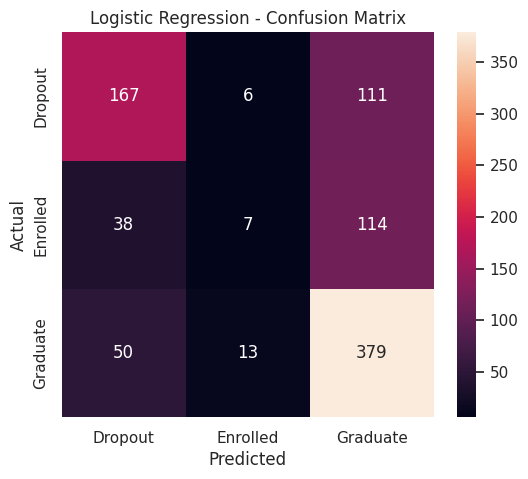

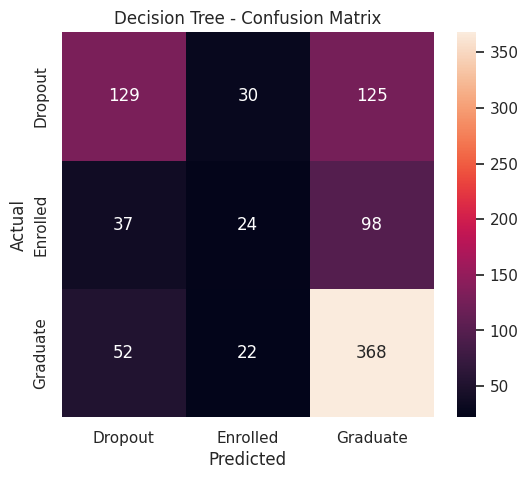

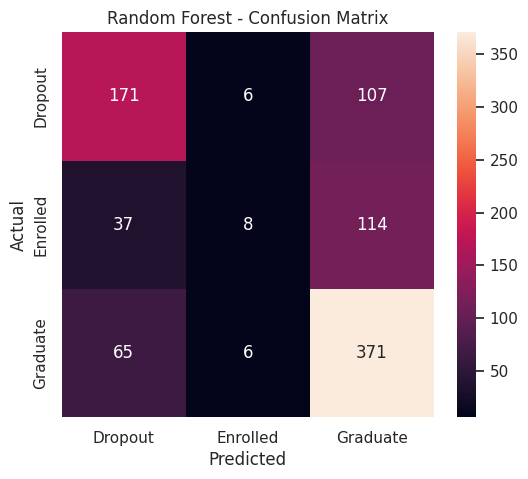

In [ ]:
# Step 29: Confusion Matrices for all three models

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Create confusion matrices
cm_logistic = confusion_matrix(y_test, y_pred_logistic)
cm_tree = confusion_matrix(y_test, y_pred_tree)
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Class labels
class_names = ["Dropout", "Enrolled", "Graduate"]


# Logistic Regression
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# Decision Tree
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# Random Forest
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# Step 30: Feature Importance using Random Forest

# Get feature importance values
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest.feature_importances_
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features")
print("--------------------------------")
display(feature_importance.head(10))

Top 10 Important Features
--------------------------------


,Feature,Importance
16,Tuition fees up to date,0.149213
19,Age at enrollment,0.101178
18,Scholarship holder,0.076735
12,Admission grade,0.076529
3,Course,0.068779
6,Previous qualification (grade),0.066142
1,Application mode,0.054601
10,Mother's occupation,0.047599
11,Father's occupation,0.046358
15,Debtor,0.039334


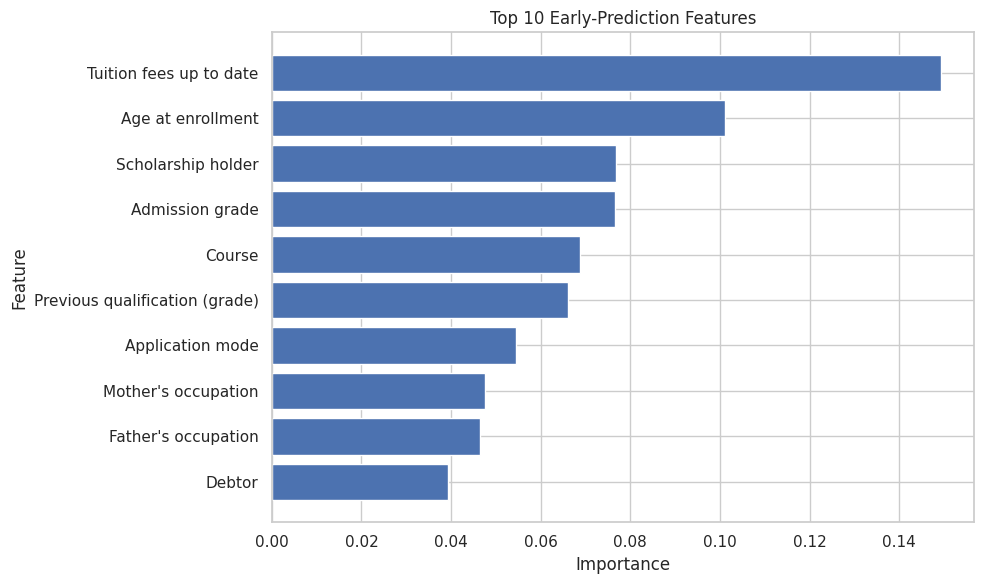

In [ ]:
# Plot Top 10 Important Features

top_features = feature_importance.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Early-Prediction Features")
plt.tight_layout()
plt.show()

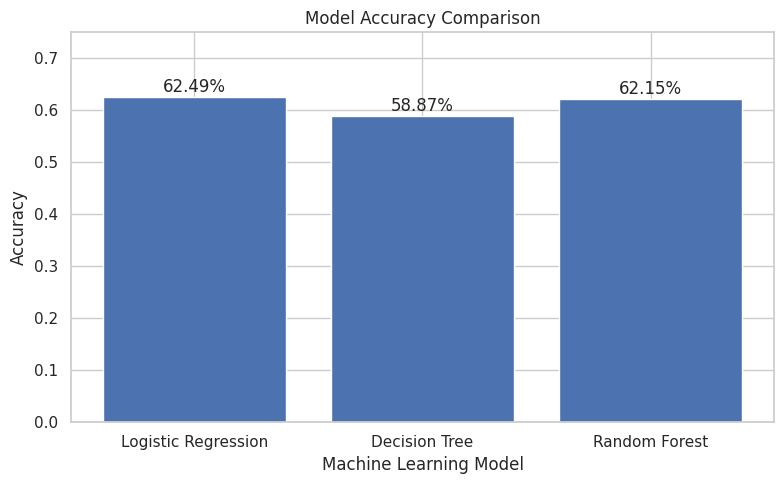

In [ ]:
# Step 31: Model Accuracy Comparison

models = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

accuracies = [
    logistic_accuracy,
    tree_accuracy,
    rf_accuracy
]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, accuracies)

plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Model")
plt.title("Model Accuracy Comparison")

# Display accuracy values above bars
for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{accuracy * 100:.2f}%",
        ha="center"
    )

plt.ylim(0, 0.75)
plt.tight_layout()
plt.show()

In [ ]:
# Step 32: Age at Enrollment vs Student Outcome

age_analysis = df.groupby("Target")["Age at enrollment"].agg(
    ["count", "mean", "median", "min", "max"]
)

print("Age at Enrollment by Student Outcome")
print("-------------------------------------")
display(age_analysis.round(2))

Age at Enrollment by Student Outcome
-------------------------------------


,count,mean,median,min,max
Target,,,,,
Dropout,1421,26.07,23.0,18,70
Enrolled,794,22.37,20.0,17,54
Graduate,2209,21.78,19.0,17,62


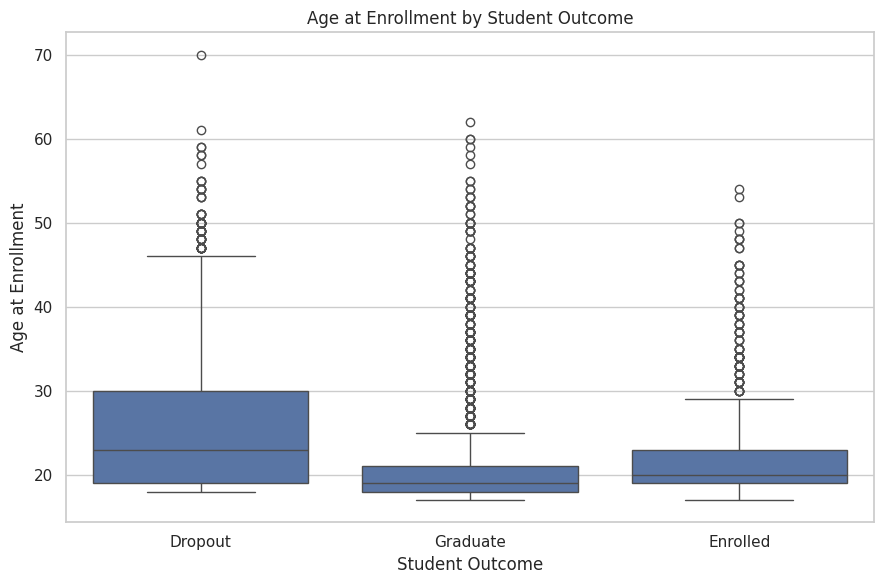

In [ ]:
# Boxplot: Age at Enrollment vs Outcome

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Target",
    y="Age at enrollment"
)

plt.title("Age at Enrollment by Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Age at Enrollment")
plt.tight_layout()
plt.show()

In [ ]:
# Step 33: Scholarship Holder vs Student Outcome

scholarship_analysis = pd.crosstab(
    df["Scholarship holder"],
    df["Target"],
    normalize="index"
) * 100

print("Student Outcome by Scholarship Status (%)")
print("------------------------------------------")
display(scholarship_analysis.round(2))

Student Outcome by Scholarship Status (%)
------------------------------------------


Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,38.71,19.97,41.32
1,12.19,11.83,75.98


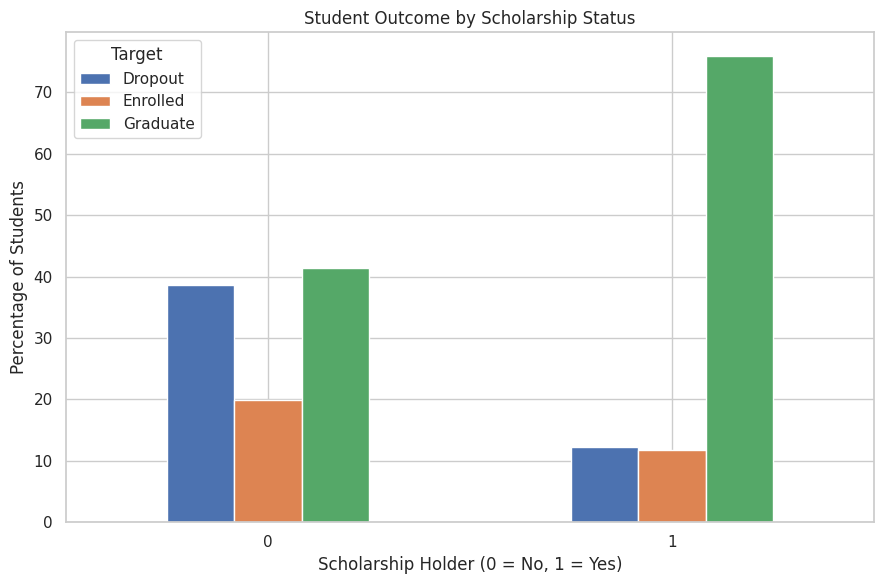

In [ ]:
# Plot Scholarship Status vs Student Outcome

scholarship_analysis.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Student Outcome by Scholarship Status")
plt.xlabel("Scholarship Holder (0 = No, 1 = Yes)")
plt.ylabel("Percentage of Students")
plt.xticks(rotation=0)
plt.legend(title="Target")
plt.tight_layout()
plt.show()

In [ ]:
# Step 34: Admission Grade vs Student Outcome

admission_analysis = df.groupby("Target")["Admission grade"].agg(
    ["count", "mean", "median", "min", "max"]
)

print("Admission Grade by Student Outcome")
print("----------------------------------")
display(admission_analysis.round(2))

Admission Grade by Student Outcome
----------------------------------


,count,mean,median,min,max
Target,,,,,
Dropout,1421,124.96,123.6,95.0,190.0
Enrolled,794,125.53,124.1,95.0,190.0
Graduate,2209,128.79,127.4,95.0,190.0


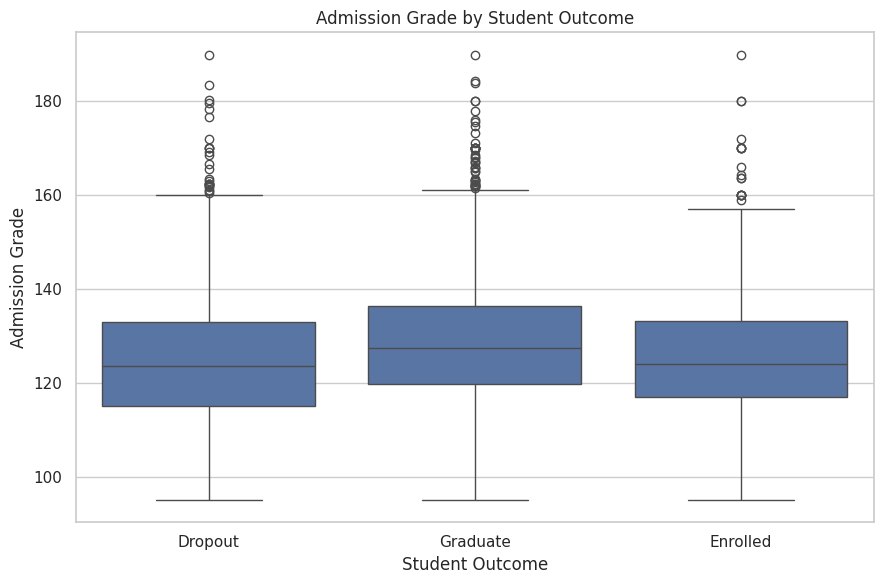

In [ ]:
# Boxplot: Admission Grade vs Outcome

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Target",
    y="Admission grade"
)

plt.title("Admission Grade by Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Admission Grade")
plt.tight_layout()
plt.show()

In [ ]:
# Step 35: Debtor Status vs Student Outcome

debtor_analysis = pd.crosstab(
    df["Debtor"],
    df["Target"],
    normalize="index"
) * 100

print("Student Outcome by Debtor Status (%)")
print("-------------------------------------")
display(debtor_analysis.round(2))

Student Outcome by Debtor Status (%)
-------------------------------------


Target,Dropout,Enrolled,Graduate
Debtor,,,
0,28.28,17.95,53.76
1,62.03,17.89,20.08


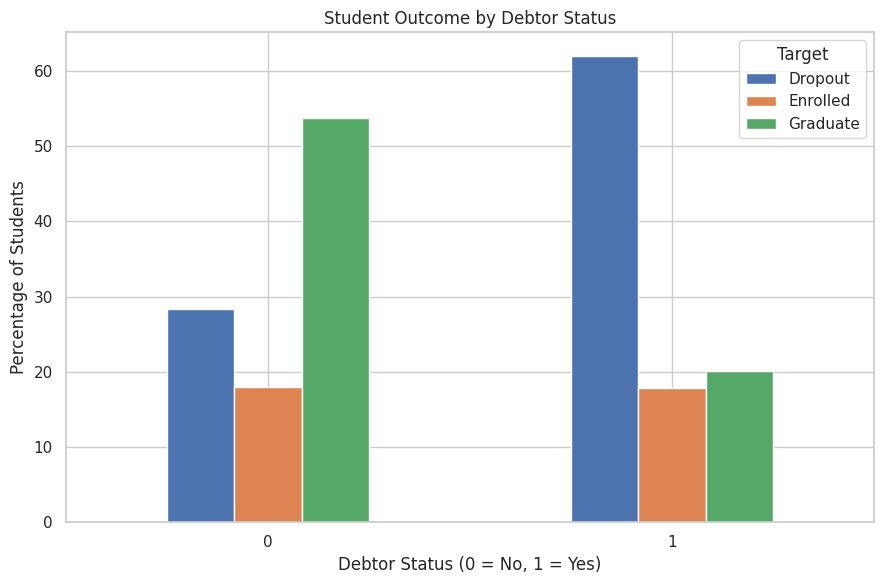

In [ ]:
# Plot Debtor Status vs Student Outcome

debtor_analysis.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Student Outcome by Debtor Status")
plt.xlabel("Debtor Status (0 = No, 1 = Yes)")
plt.ylabel("Percentage of Students")
plt.xticks(rotation=0)
plt.legend(title="Target")
plt.tight_layout()
plt.show()

In [ ]:
# Step 36: Final Model Comparison

# Sort models by accuracy
final_comparison = model_comparison.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL COMPARISON")
print("=" * 60)

display(final_comparison)

FINAL MODEL COMPARISON


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1-Score
0,Logistic Regression,0.6249,0.5719,0.6249,0.5744
1,Random Forest,0.6215,0.5859,0.6215,0.5715
2,Decision Tree,0.5887,0.5576,0.5887,0.5575


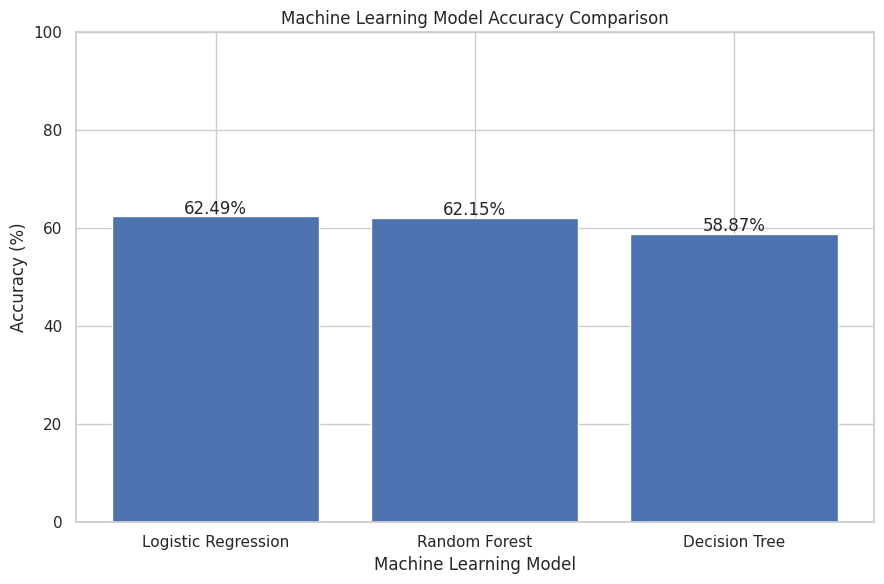

In [ ]:
# Accuracy Comparison

plt.figure(figsize=(9, 6))

plt.bar(
    final_comparison["Model"],
    final_comparison["Accuracy"] * 100
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")

# Display accuracy values above bars
for i, value in enumerate(final_comparison["Accuracy"] * 100):
    plt.text(
        i,
        value + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [ ]:
# Step 38: Final Results Summary

print("=" * 70)
print("FINAL RESULTS SUMMARY")
print("=" * 70)

print("\n1. DATASET")
print("Students:", df.shape[0])
print("Original features:", df.shape[1] - 1)
print("Early-prediction features:", X_early.shape[1])

print("\n2. TARGET DISTRIBUTION")
print(df["Target"].value_counts())

print("\n3. MACHINE LEARNING RESULTS")
display(final_comparison)

print("\n4. STATISTICAL ANALYSIS")
print("Chi-square test: Scholarship Holder vs Target")
print("Chi-square statistic: 409.9431")
print("p-value: < 0.001")

print("\nANOVA: Age at Enrollment vs Target")
print("F-statistic: 154.7121")
print("p-value: < 0.001")

print("\n5. BEST MODEL")
print("Logistic Regression")
print("Accuracy: 62.49%")

print("\n6. BEST DROPOUT RECALL")
print("Random Forest")
print("Dropout Recall: 60%")

FINAL RESULTS SUMMARY

1. DATASET
Students: 4424
Original features: 36
Early-prediction features: 24

2. TARGET DISTRIBUTION
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

3. MACHINE LEARNING RESULTS


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1-Score
0,Logistic Regression,0.6249,0.5719,0.6249,0.5744
1,Random Forest,0.6215,0.5859,0.6215,0.5715
2,Decision Tree,0.5887,0.5576,0.5887,0.5575



4. STATISTICAL ANALYSIS
Chi-square test: Scholarship Holder vs Target
Chi-square statistic: 409.9431
p-value: < 0.001

ANOVA: Age at Enrollment vs Target
F-statistic: 154.7121
p-value: < 0.001

5. BEST MODEL
Logistic Regression
Accuracy: 62.49%

6. BEST DROPOUT RECALL
Random Forest
Dropout Recall: 60%
